# Plot R-A curve

In [50]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d


def read_file(file_path):
    data = []
    with open(file_path, 'r') as file:
        for line in file:
            parts = line.split()
            row = []
            for i, value in enumerate(parts):
                if i in [2, 3, 4]: 
                    try:
                        row.append(float(value))
                    except ValueError:
                        row.append(None) 
                else:
                    row.append(float(value))
            data.append(row)
    return data


def plot_txt_files(folder_path, lower_bpp=0, upper_bpp=24):
    x_values_lsit = []
    y_values_list = []
    filename_list = []
    color_list = ["r","g","orange"]
    # for idx, filename in enumerate(["ours.txt", "google.txt", "autojpeg.txt", "OptS.txt"]):
    for idx, filename in enumerate(["LJCD (ours).txt", "Google (Luo et al.).txt", "AutoJPEG (Xie et al.).txt"]):
    # for idx, filename in enumerate(["ours.txt", "google.txt"]):
    # for idx, filename in enumerate(["ours.txt"]):
        file_path = os.path.join(folder_path, filename)
        data = read_file(file_path)
        x_values = [row[0] for row in data if row[0] is not None]  # bpp
        y_values = [row[1] for row in data if row[1] is not None]  # acc
        
        filtered_data = [(x, y) for x, y in zip(x_values, y_values) if (x>=lower_bpp and x<=upper_bpp)]
        x_values, y_values = zip(*filtered_data) if filtered_data else ([], [])
        if x_values and y_values:
            x_values_lsit.append(x_values)
            y_values_list.append(y_values)
            filename_list.append(filename.removesuffix('.txt'))
            plt.plot(x_values, y_values, label=filename.removesuffix('.txt'), clip_on=True, color=color_list[idx])
    return x_values_lsit, y_values_list, filename_list


def plot_JPEG_baseline(path='./save/imagenet/mobilenet_v2/HDQ.txt', lower_qf=1, upper_qf=100, lower_bpp=0, upper_bpp=24):
    data = read_file(path)
    # plot baseline for HDQ
    QF_ls = [int(row[0]) for row in data]
    HDQ_y = [row[1] for row in data]
    HDQ_x = [row[2] for row in data]
    
    sorted_lists = [(qf, y, x) for qf, y, x in sorted(zip(QF_ls, HDQ_y, HDQ_x)) if (lower_qf<=qf and qf<=upper_qf) and (lower_bpp<=x and x<=upper_bpp)]

    QF_ls, HDQ_y, HDQ_x = map(list, zip(*sorted_lists))
    
    plt.plot(HDQ_x, HDQ_y, label="JPEG", color='b', linestyle='dashed', clip_on=True)
    # for i, (x, y) in enumerate(zip(HDQ_x, HDQ_y)):
    #     if QF_ls[i] % 10 == 0:
    #         plt.annotate(str(QF_ls[i]), (x, y), textcoords="offset points", xytext=(5,-7), ha='center', fontsize=8)

    return HDQ_x, HDQ_y


def plot_acc_gain(x1, y1, x2, y2, label=''):
    baseline_interpolator = interp1d(x2, y2, kind='linear', fill_value='extrapolate')
    y2_interp = baseline_interpolator(x1)
    acc_gain = y1 - y2_interp
    max_idx = np.argmax(acc_gain)
    print(x1[max_idx])
    print(y1[max_idx])
    print(acc_gain[max_idx])
    plt.plot(x1, acc_gain, label=label, clip_on=True)


dataset="imagenet"
# dataset="CUB200"

# model="resnet18"
# model="mobilenet_v2"
# model="Mnasnet"
# model="Swin_T"
model="ConvNeXt_tiny"


base_path = './save/{}/{}'.format(dataset,model)
result_folder = "./save/Results"
plot_path = os.path.join(result_folder, "{}/{}".format(dataset,model))

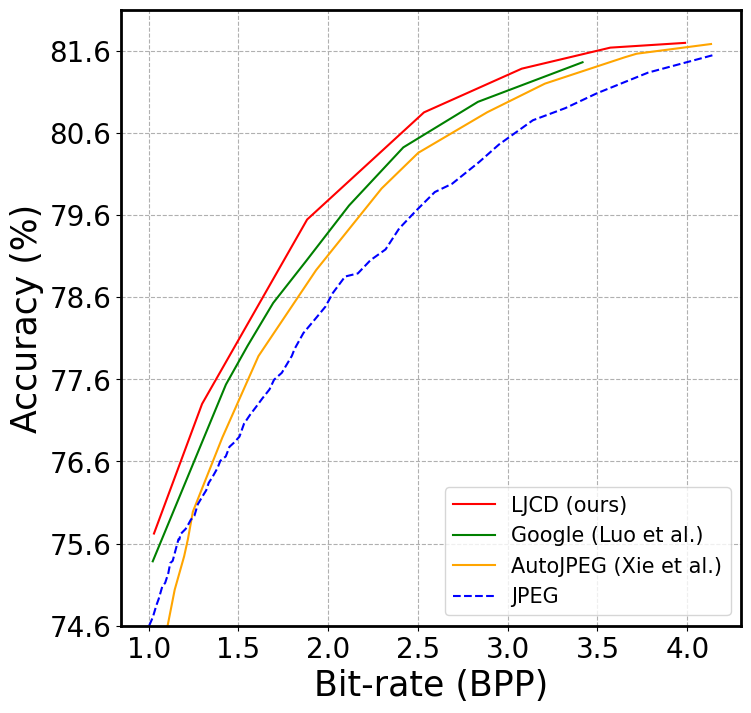

In [51]:
plt.figure(figsize=(8,8))
font = 20
# Set the default text font size
# plt.rc('font', size=14, weight='bold')
plt.rc('figure', figsize = (8,6))
# plt.rc('figure', autolayout = True)
plt.rc('font', size=font+4)
# Set the axes title font size
plt.rc('axes', titlesize=font)
# Set the axes labels font size
plt.rc('axes', labelsize=font)
# Set the font size for x tick labels
plt.rc('xtick', labelsize=font)
# Set the font size for y tick labels
plt.rc('ytick', labelsize=font)
# Set the legend font size
plt.rc('legend', fontsize=15)
# Set the font size of the figure title
plt.rc('figure', titlesize=font)

# lower_bpp=0.2
# upper_bpp=2.0

lower_bpp=1.0
upper_bpp=4.2

X_list, Y_list, fn_list = plot_txt_files(plot_path, lower_bpp=lower_bpp, upper_bpp=upper_bpp)
x2, y2 = plot_JPEG_baseline(path=os.path.join(plot_path, "JPEG_baseline.txt"), lower_bpp=lower_bpp, upper_bpp=upper_bpp)

plt.xlabel('Bit-rate (BPP)', fontsize=font+5)
plt.ylabel('Accuracy (%)', fontsize=font+5)
x_min, x_max = plt.xlim()
y_min, y_max = plt.ylim()
# x_range = np.maximum(np.round((x_max - x_min) / 4, 1), 0.02)
# y_range = np.maximum(np.round((y_max - y_min) / 4, 1), 0.02)
plt.ylim(min(y2), y_max)
plt.xticks(np.arange(lower_bpp, upper_bpp, 0.5))
plt.yticks(np.arange(np.round(min(y2), 1), np.round(y_max, 1), 1.0))
# plt.title("{}, {}: ".format(dataset, model) + 'Acc vs BPP') 
plt.legend(loc="lower right")
plt.grid(True, linestyle='--')
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(2)
plt.show()

0.250019049348453
49.94822311401367
9.142309865384554
1.099789748235143
64.75664520263672
0.297093640198824
1.932026490486816
64.44597625732422
-1.119208595358245


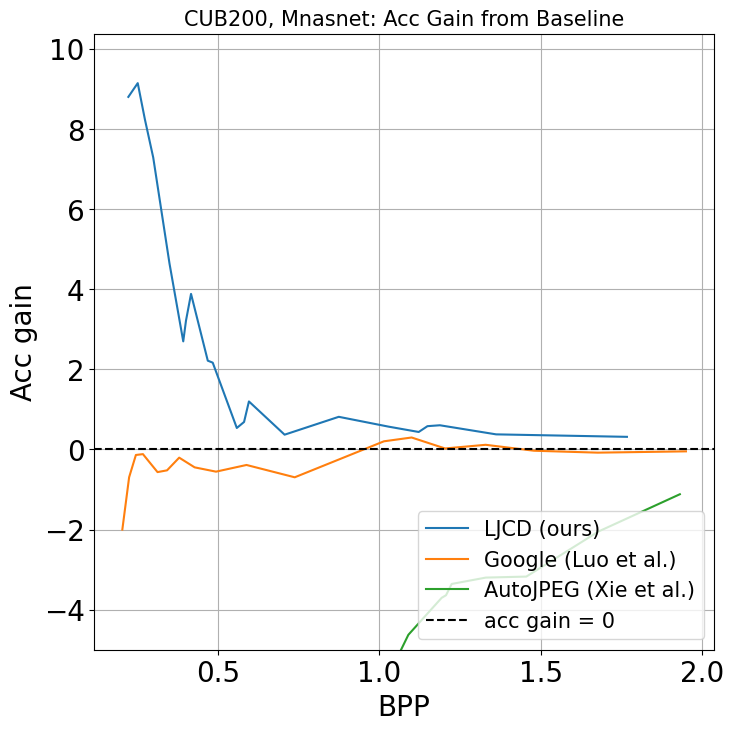

In [25]:
# plot acc gain
plt.figure(figsize=(8,8))
font = 20
# Set the default text font size
# plt.rc('font', size=14, weight='bold')
plt.rc('figure', figsize = (8,6))
# plt.rc('figure', autolayout = True)
plt.rc('font', size=font+4)
# Set the axes title font size
plt.rc('axes', titlesize=font)
# Set the axes labels font size
plt.rc('axes', labelsize=font)
# Set the font size for x tick labels
plt.rc('xtick', labelsize=font)
# Set the font size for y tick labels
plt.rc('ytick', labelsize=font)
# Set the legend font size
plt.rc('legend', fontsize=15)
# Set the font size of the figure title
plt.rc('figure', titlesize=font)

for idx, (x1, y1, fn) in enumerate(zip(X_list, Y_list, fn_list)):
    plot_acc_gain(x1, y1, x2, y2, fn)

plt.axhline(y=0, color='black', linestyle='--', label="acc gain = 0")
x_min, x_max = plt.xlim()
y_min, y_max = plt.ylim()
# x_range = np.maximum(np.round((x_max-x_min)/15,1), 0.01)
# y_range = np.maximum(np.round((y_max-y_min)/15,1), 0.01)
# plt.xticks(np.arange(np.round(x_min,1), np.round(x_max,1), x_range))
# plt.yticks(np.arange(np.round(y_min,1), np.round(y_max,1), y_range))
plt.ylim(-5, y_max)
plt.title("{}, {}: ".format(dataset, model) + 'Acc Gain from Baseline', fontsize=15)
plt.xlabel('BPP')
plt.ylabel('Acc gain')
plt.legend(loc="lower right")
plt.grid()
plt.show()

# Plot Correlation

10000
P-value: 0.0
10000
P-value: 0.0
10000
P-value: 0.0


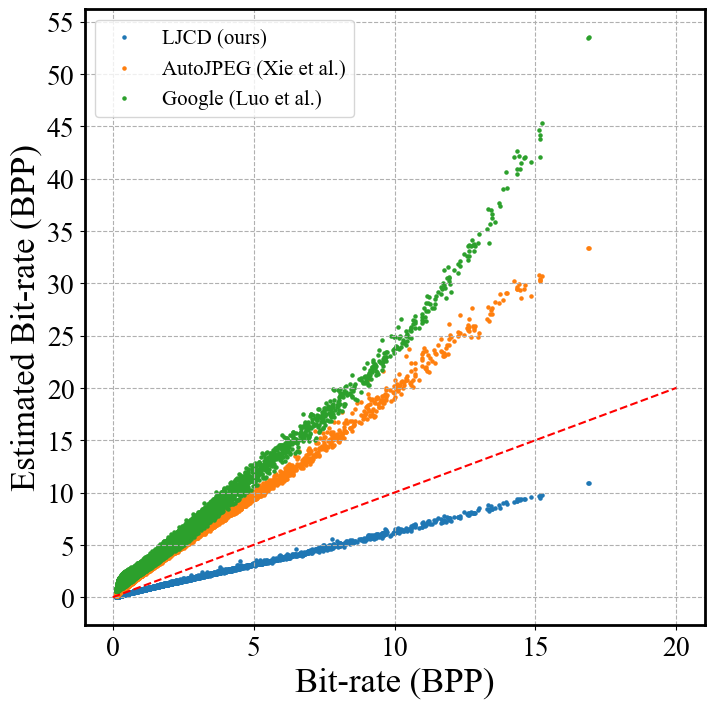

In [ ]:
from scipy.stats import pearsonr
import numpy as np


def plot_correlation_ours(path):
    Y_data = read_file(path)
    print(len(Y_data))
    Entropy = [(row[1]+row[2]+row[3]+row[4]) for row in Y_data] # entropy
    bpp = [(row[0]) for row in Y_data] # test bpp

    mse = np.mean((np.array(Entropy) - np.array(bpp)) ** 2)
    correlation, p_value = pearsonr(Entropy, bpp)
    print(f"P-value: {p_value}")

    # plt.scatter(bpp, Entropy, s=5, label="ours: Correlation: {:.5f}, MSE: {:.5f}".format(correlation, mse), alpha=0.5)
    plt.scatter(bpp, Entropy, s=5, label="LJCD (ours)")
    return 


def plot_correlation_autojpeg(path):
    Y_data = read_file(path)
    print(len(Y_data))
    Entropy = [(row[1]) for row in Y_data] # entropy
    bpp = [(row[0]) for row in Y_data] # test bpp

    mse = np.mean((np.array(Entropy) - np.array(bpp)) ** 2)
    correlation, p_value = pearsonr(Entropy, bpp)
    print(f"P-value: {p_value}")

    # plt.scatter(bpp, Entropy, s=5, label="autojpeg: Correlation: {:.5f}, MSE: {:.5f}".format(correlation, mse), alpha=0.5)
    plt.scatter(bpp, Entropy, s=5, label="AutoJPEG (Xie et al.)")
    return 


def plot_correlation_google(path):
    Y_data = read_file(path)
    print(len(Y_data))
    Entropy = [(row[1]+row[2]+row[3]+row[4]) for row in Y_data] # entropy
    bpp = [(row[0]) for row in Y_data] # test bpp

    mse = np.mean((np.array(Entropy) - np.array(bpp)) ** 2)
    correlation, p_value = pearsonr(Entropy, bpp)
    print(f"P-value: {p_value}")

    # plt.scatter(bpp, Entropy, s=5, label="google: Correlation: {:.5f}, MSE: {:.5f}".format(correlation, mse), alpha=0.5)
    plt.scatter(bpp, Entropy, s=5
                , label="Google (Luo et al.)")
    return 


plt.figure(figsize=(8, 8))
plot_correlation_ours("./save/Results/ours_BPP_Entropy_correlation_alpha_100.txt")
plot_correlation_autojpeg("./save/Results/autojpeg_BPP_Entropy_correlation.txt")
plot_correlation_google("./save/Results/google_BPP_Entropy_correlation.txt")
plt.plot([0, 20], [0, 20], color='red', linestyle='--')

plt.rcParams["font.family"] = "Times New Roman"
font = 20
# Set the default text font size
# plt.rc('font', size=14, weight='bold')
plt.rc('figure', figsize = (8,6))
# plt.rc('figure', autolayout = True)
plt.rc('font', size=font+4)
# Set the axes title font size
plt.rc('axes', titlesize=font)
# Set the axes labels font size
plt.rc('axes', labelsize=font)
# Set the font size for x tick labels
plt.rc('xtick', labelsize=font)
# Set the font size for y tick labels
plt.rc('ytick', labelsize=font)
# Set the legend font size
plt.rc('legend', fontsize=15)
# Set the font size of the figure title
plt.rc('figure', titlesize=font)

# plt.title(f'Entropy vs BPP')
plt.xlabel('Bit-rate (BPP)', fontsize=font+5)
plt.ylabel('Estimated Bit-rate (BPP)', fontsize=font+5)
plt.grid(True, linestyle='--')
plt.legend(loc="upper left")
x_min, x_max = plt.xlim()
y_min, y_max = plt.ylim()
# plt.xticks(np.arange(0, np.round(x_max), 5))
plt.yticks(np.arange(0, np.round(y_max), 5))
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(2)
plt.show()

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d


def read_file(file_path):
    data = []
    with open(file_path, 'r') as file:
        for line in file:
            parts = line.split()
            row = []
            for i, value in enumerate(parts):
                if i in [2, 3, 4]:
                    try:
                        row.append(float(value))
                    except ValueError:
                        row.append(None)
                else:
                    row.append(float(value))
            data.append(row)
    return data


def plot_txt_files(folder_path, lower_bpp=0, upper_bpp=24):
    x_values_lsit = []
    y_values_list = []
    filename_list = []

    color_list = ["r","g","orange","b"]
    line_list = ["-", '--', '--', '-']
    # for idx, filename in enumerate(["Single-trained.txt", "MNASNet→ResNet18.txt", "MobileNetV2→ResNet18.txt", "Joint-trained.txt"]):
    # for idx, filename in enumerate(["Single-trained.txt", "ResNet18→MobileNetV2.txt", "MNASNet→MobileNetV2.txt", "Joint-trained.txt"]):
    for idx, filename in enumerate(["Single Model Optimization.txt", "Transfer from ResNet18.txt", "Transfer from MobileNetV2.txt", "Multi Model Co-Train.txt"]):
        file_path = os.path.join(folder_path, filename)
        data = read_file(file_path)
        x_values = [row[0] for row in data if row[0] is not None]  # bpp
        y_values = [row[1] for row in data if row[1] is not None]  # acc
        
        filtered_data = [(x, y) for x, y in zip(x_values, y_values) if (x>=lower_bpp and x<=upper_bpp)]
        x_values, y_values = zip(*filtered_data) if filtered_data else ([], [])
        if x_values and y_values:
            x_values_lsit.append(x_values)
            y_values_list.append(y_values)
            filename_list.append(filename.removesuffix('.txt'))
            plt.plot(x_values, y_values, label=filename.removesuffix('.txt'), clip_on=True, color=color_list[idx], linestyle=line_list[idx])
    return x_values_lsit, y_values_list, filename_list


def plot_JPEG_baseline(path='./save/imagenet/mobilenet_v2/HDQ.txt', lower_qf=1, upper_qf=100, lower_bpp=0, upper_bpp=24):
    data = read_file(path)
    # plot baseline for HDQ
    QF_ls = [int(row[0]) for row in data]
    HDQ_y = [row[1] for row in data]
    HDQ_x = [row[2] for row in data]
    
    sorted_lists = [(qf, y, x) for qf, y, x in sorted(zip(QF_ls, HDQ_y, HDQ_x)) if (lower_qf<=qf and qf<=upper_qf) and (lower_bpp<=x and x<=upper_bpp)]

    QF_ls, HDQ_y, HDQ_x = map(list, zip(*sorted_lists))
    
    plt.plot(HDQ_x, HDQ_y, label="JPEG", color='k', linestyle='dashed', clip_on=True)
    # for i, (x, y) in enumerate(zip(HDQ_x, HDQ_y)):
    #     if QF_ls[i] % 10 == 0:
    #         plt.annotate(str(QF_ls[i]), (x, y), textcoords="offset points", xytext=(5,-7), ha='center', fontsize=8)

    return HDQ_x, HDQ_y


def plot_acc_gain(x1, y1, x2, y2, label=''):
    baseline_interpolator = interp1d(x2, y2, kind='linear', fill_value='extrapolate')
    y2_interp = baseline_interpolator(x1)
    acc_gain = y1 - y2_interp
    max_idx = np.argmax(acc_gain)
    print(x1[max_idx])
    print(y1[max_idx])
    print(acc_gain[max_idx])
    print('')
    plt.plot(x1, acc_gain, label=label, clip_on=True)


# model="resnet18"
# model="mobilenet_v2"
model="Mnasnet"

base_path = './save/CUB200/{}'.format(model)
result_folder = "./save/Results"
plot_path = os.path.join(result_folder, "CUB200/{}".format(model))

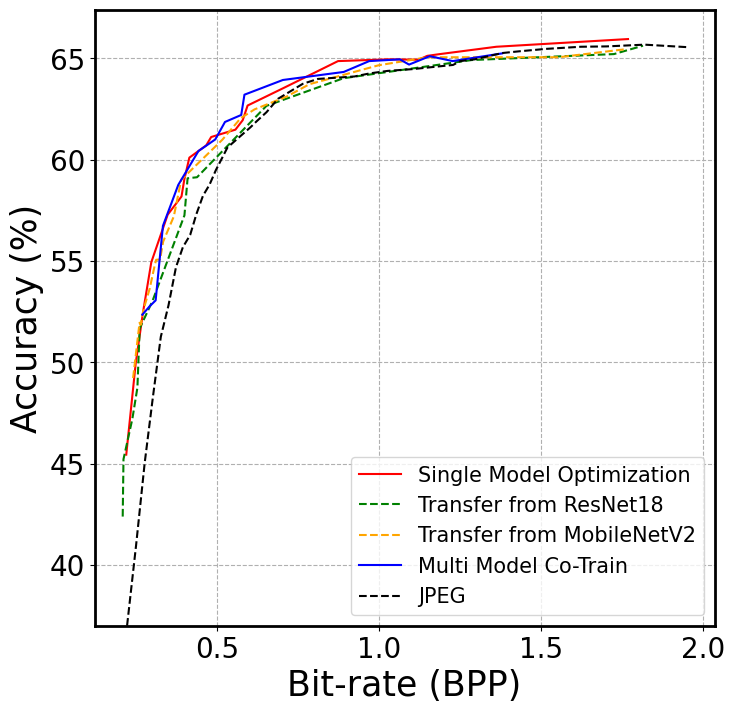

In [3]:
plt.figure(figsize=(8,8))
font = 20
# Set the default text font size
# plt.rc('font', size=14, weight='bold')
plt.rc('figure', figsize = (8,6))
# plt.rc('figure', autolayout = True)
plt.rc('font', size=font+4)
# Set the axes title font size
plt.rc('axes', titlesize=font)
# Set the axes labels font size
plt.rc('axes', labelsize=font)
# Set the font size for x tick labels
plt.rc('xtick', labelsize=font)
# Set the font size for y tick labels
plt.rc('ytick', labelsize=font)
# Set the legend font size
plt.rc('legend', fontsize=15)
# Set the font size of the figure title
plt.rc('figure', titlesize=font)

lower_bpp=0.2
upper_bpp=2

X_list, Y_list, fn_list = plot_txt_files(plot_path, lower_bpp=lower_bpp, upper_bpp=upper_bpp)
x2, y2 = plot_JPEG_baseline(path=os.path.join(plot_path, "JPEG_baseline.txt"), lower_bpp=lower_bpp, upper_bpp=upper_bpp)

plt.xlabel('Bit-rate (BPP)', fontsize=font+5)
plt.ylabel('Accuracy (%)', fontsize=font+5)
x_min, x_max = plt.xlim()
y_min, y_max = plt.ylim()
x_range = np.maximum(np.round((x_max - x_min) / 4, 1), 0.02)
y_range = np.maximum(np.round((y_max - y_min) / 4, 1), 0.02)
# plt.xticks(np.arange(np.round(x_min, 1), np.round(x_max, 1), x_range))
# plt.yticks(np.arange(np.round(y_min, 1), np.round(y_max, 1), y_range))
plt.ylim(min(y2), y_max)
# plt.title("CUB200, {}: ".format(model) + 'Acc vs BPP') 
plt.legend(loc="lower right")
plt.grid(True, linestyle='--')
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(2)
plt.show()

0.250019049348453
49.94822311401367
9.142309865384554

0.212357097465775
45.21919250488281
9.791917275488167

0.241971370830623
49.22333526611328
9.566739763346547

0.270410911335353
52.34725570678711
8.42958337805792



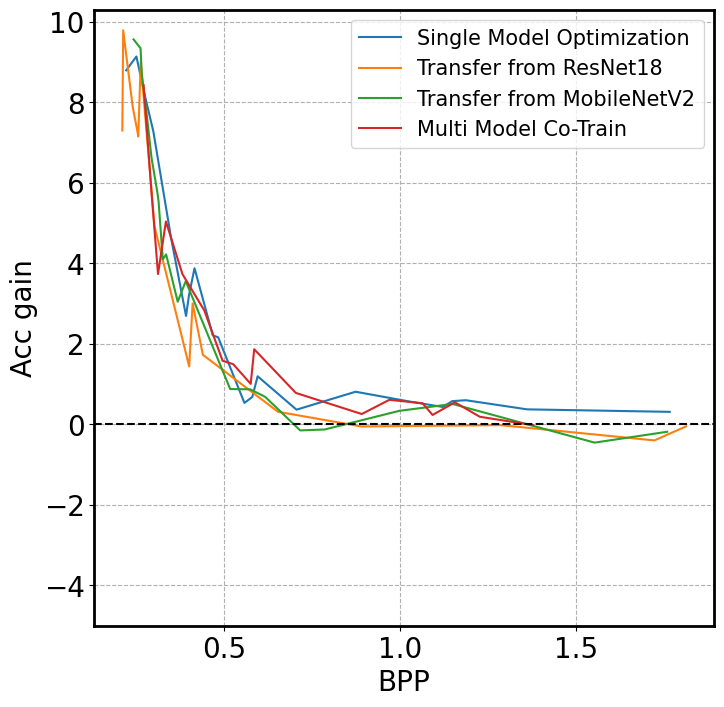

In [4]:
# plot acc gain
plt.figure(figsize=(8,8))
font = 20
# Set the default text font size
# plt.rc('font', size=14, weight='bold')
plt.rc('figure', figsize = (8,6))
# plt.rc('figure', autolayout = True)
plt.rc('font', size=font+4)
# Set the axes title font size
plt.rc('axes', titlesize=font)
# Set the axes labels font size
plt.rc('axes', labelsize=font)
# Set the font size for x tick labels
plt.rc('xtick', labelsize=font)
# Set the font size for y tick labels
plt.rc('ytick', labelsize=font)
# Set the legend font size
plt.rc('legend', fontsize=15)
# Set the font size of the figure title
plt.rc('figure', titlesize=font)

for idx, (x1, y1, fn) in enumerate(zip(X_list, Y_list, fn_list)):
    plot_acc_gain(x1, y1, x2, y2, fn)

plt.axhline(y=0, color='black', linestyle='--')
x_min, x_max = plt.xlim()
y_min, y_max = plt.ylim()
# x_range = np.maximum(np.round((x_max-x_min)/15,1), 0.01)
# y_range = np.maximum(np.round((y_max-y_min)/15,1), 0.01)
# plt.xticks(np.arange(np.round(x_min,1), np.round(x_max,1), x_range))
# plt.yticks(np.arange(np.round(y_min,1), np.round(y_max,1), y_range))
plt.ylim(-5, y_max)
# plt.title("CUB200, {}: ".format(model) + 'Acc Gain from Baseline', fontsize=15)
plt.xlabel('BPP')
plt.ylabel('Acc gain')
plt.legend(loc="upper right")
plt.grid(True, linestyle='--')
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(2)
plt.show()

In [60]:

def zigzag(matrix):
    zigzag = np.array([[0, 1, 5, 6, 14, 15, 27, 28],
                        [2, 4, 7, 13, 16, 26, 29, 42],
                        [3, 8, 12, 17, 25, 30, 41, 43],
                        [9, 11, 18, 24, 31, 40, 44, 53],
                        [10, 19, 23, 32, 39, 45, 52, 54],
                        [20, 22, 33, 38, 46, 51, 55, 60],
                        [21, 34, 37, 47, 50, 56, 59, 61],
                        [35, 36, 48, 49, 57, 58, 62, 63]])
    matrix_size = np.shape(matrix)
    vector_size = np.shape(zigzag)
    if matrix_size != vector_size:
        raise ValueError("The matrix size does not match the vector size.")
    vector = np.zeros(matrix_size[0] * matrix_size[1])
    for i in range(matrix_size[0]):
        for j in range(matrix_size[1]):
            index = zigzag[i, j]
            vector[index] = matrix[i, j]
    return vector


def quantizationTable(QF=50, Luminance=True):
    quantizationTableData = np.ones((8, 8), dtype=np.float32)
    if QF == 100:
        return quantizationTableData

    if Luminance == True:
        quantizationTableData = np.array([[16, 11, 10, 16, 24, 40, 51, 61],
                                          [12, 12, 14, 19, 26, 58, 60, 55],
                                          [14, 13, 16, 24, 40, 57, 69, 56],
                                          [14, 17, 22, 29, 51, 87, 80, 62],
                                          [18, 22, 37, 56, 68, 109, 103, 77],
                                          [24, 35, 55, 64, 81, 104, 113, 92],
                                          [49, 64, 78, 87, 103, 121, 120, 101],
                                          [72, 92, 95, 98, 112, 100, 103, 99]])
    else:
        quantizationTableData = np.array([[17, 18, 24, 47, 99, 99, 99, 99],
                                          [18, 21, 26, 66, 99, 99, 99, 99],
                                          [24, 26, 56, 99, 99, 99, 99, 99],
                                          [47, 66, 99, 99, 99, 99, 99, 99],
                                          [99, 99, 99, 99, 99, 99, 99, 99],
                                          [99, 99, 99, 99, 99, 99, 99, 99],
                                          [99, 99, 99, 87, 99, 99, 99, 99],
                                          [99, 99, 99, 99, 99, 99, 99, 99]])
    if QF >= 1:
        if QF < 50:
            S = 5000 / QF
        else:
            S = 200 - 2 * QF

        for i in range(8):
            for j in range(8):
                q = (50 + S * quantizationTableData[i][j]) / 100
                q = np.clip(np.floor(q), 1, 255)
                quantizationTableData[i][j] = q
    return quantizationTableData


def plot_q_table(filepaths, lum=True, epoch_choose=-1):
    with open(os.path.join(filepaths, "lum_q_table.txt"), "r") as lum_file:
        lum_lines = lum_file.read()
    lum_tables = lum_lines.split("\n\n")[:-1]
    
    with open(os.path.join(filepaths, "chrom_q_table.txt"), "r") as chrom_file:
        chrom_lines = chrom_file.read()
    chrom_tables = chrom_lines.split("\n\n")[:-1]
    
    if len(lum_tables)==102:
        lum_tables = lum_tables[1:]
        chrom_tables = chrom_tables[1:]
    print("len of q_tables", len(lum_tables))
    
    # plot lum q_table
    for epoch, (lum_table, chrom_table) in enumerate(zip(lum_tables, chrom_tables)): 
        if epoch_choose >= 0: 
            # only print the lun/chrom qtable for this epoch
            if epoch != epoch_choose and epoch != 0:
                continue
        elif epoch % 5 != 0: 
            continue
    
        Lum_matrix = np.array([list(map(float, row.split(","))) for row in lum_table.split("\n")])
        Lum_matrix = zigzag(Lum_matrix).flatten()
        
        chrom_matrix = np.array([list(map(float, row.split(","))) for row in chrom_table.split("\n")])
        chrom_matrix = zigzag(chrom_matrix).flatten()
        
        if lum:
            if epoch==0:
                plt.plot(Lum_matrix, label="Inital", color="b")
            else:
                plt.plot(Lum_matrix, label="Final", color="r")
        else:
            if epoch==0:
                plt.plot(chrom_matrix, label="Inital", color="b")
            else:
                plt.plot(chrom_matrix, label="Final", color="r")


def plot_q_table_QF(QF, lum=True):
    matrix_lum = quantizationTable(QF, Luminance=lum)
    matrix_lum = zigzag(matrix_lum).flatten()
    plt.plot(matrix_lum, label="JPEG", color="g")

len of q_tables 21


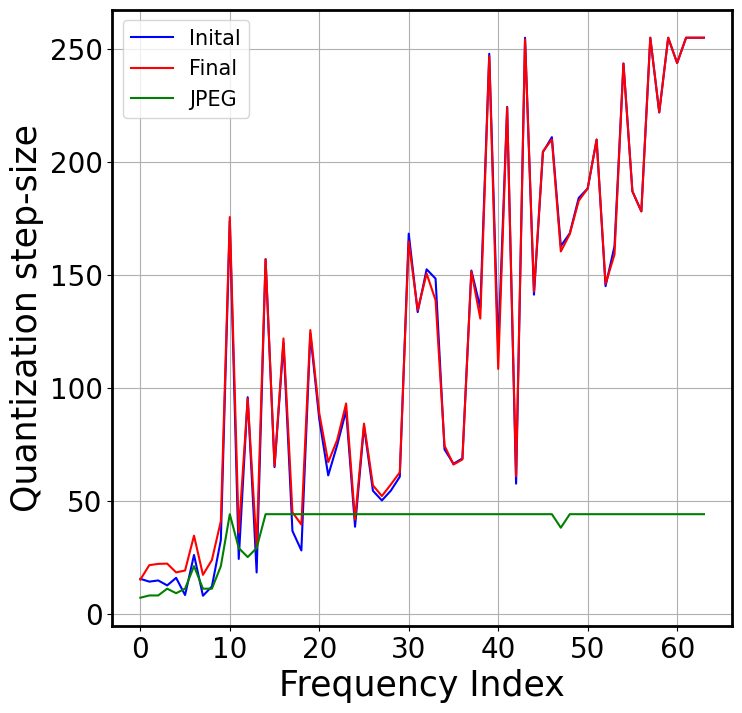

In [62]:
plt.figure(figsize=(8,8))

font = 20
# Set the default text font size
# plt.rc('font', size=14, weight='bold')
plt.rc('figure', figsize = (8,6))
# plt.rc('figure', autolayout = True)
plt.rc('font', size=font+4)
# Set the axes title font size
plt.rc('axes', titlesize=font)
# Set the axes labels font size
plt.rc('axes', labelsize=font)
# Set the font size for x tick labels
plt.rc('xtick', labelsize=font)
# Set the font size for y tick labels
plt.rc('ytick', labelsize=font)
# Set the legend font size
plt.rc('legend', fontsize=15)
# Set the font size of the figure title
plt.rc('figure', titlesize=font)

# plot_q_table(os.path.join(os.path.join(base_path, "JPEG_lr_0.01_alpha_100.0_weight_0.5_0.5_sensitivity_50.0"), "trial_1/Q_tables"), lum=True, epoch_choose=10)
plot_q_table(os.path.join(os.path.join(base_path, "JPEG_lr_0.01_alpha_100.0_weight_0.5_0.5_sensitivity_50.0"), "trial_1/Q_tables"), lum=False, epoch_choose=10)

# plot_q_table_QF(78, True)
plot_q_table_QF(78, False)

plt.xlabel('Frequency Index', fontsize=font+5)
plt.ylabel('Quantization step-size', fontsize=font+5)
plt.legend()
plt.grid(True)

ax = plt.gca()
plt.subplots_adjust(hspace=0.3)
for spine in ax.spines.values():
    spine.set_linewidth(2)
plt.show()